# 02 — Modelagem com Random Forest (notebook de testes)

Duas tarefas, espelhando o artigo (Liu et al. 2020):
1. **Detecção:** câncer (CRC + STAD) vs saudável (NC)
2. **Tecido de origem (TOO):** CRC vs STAD, só nas amostras com câncer
3. **Fluxo hierárquico:** aplica (1) e, nos positivos, (2)

Regras anti-vazamento:
- Toda etapa que **olha os dados de várias amostras** (filtro de promotores, seleção de features) fica **dentro do `Pipeline`** → é ajustada só no treino de cada fold.
- `log2(CPM+1)` é aplicado amostra a amostra (não usa estatística de outras amostras) → pode ficar fora.
- Cada amostra do GEO é um indivíduo diferente (um GSM por pessoa) → não há risco de o mesmo paciente cair em treino e teste.

In [1]:
import sys, gzip, urllib.request
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/<usuario>/GenomicaComputacional.git"  # TODO: ajustar após criar o repo
if IN_COLAB and not Path("GenomicaComputacional").exists():
    !git clone -q {REPO_URL}

def find_root():
    for p in [Path.cwd(), *Path.cwd().parents, Path("GenomicaComputacional").resolve()]:
        if (p / "PLANO_EXECUCAO.md").exists():
            return p
    return Path.cwd()

ROOT = find_root()
RAW, REF = ROOT / "data" / "raw", ROOT / "data" / "reference"
FIG, TAB = ROOT / "results" / "figures", ROOT / "results" / "tables"
for d in (RAW, FIG, TAB): d.mkdir(parents=True, exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import (StratifiedKFold, RepeatedStratifiedKFold, GridSearchCV,
                                     train_test_split, cross_val_predict)
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             roc_auc_score, roc_curve, f1_score, precision_score, recall_score, accuracy_score)
from sklearn.inspection import permutation_importance

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## 1. Dados (mesmo pré-processamento validado na EDA)

In [2]:
GEO_FTP = "https://ftp.ncbi.nlm.nih.gov/geo/series/GSE186nnn/GSE186575"
FILES = {"GSE186575_DNA-Met_CPM_matrix_promoter.txt.gz": f"{GEO_FTP}/suppl/GSE186575_DNA-Met_CPM_matrix_promoter.txt.gz",
         "GSE186575_series_matrix.txt.gz": f"{GEO_FTP}/matrix/GSE186575_series_matrix.txt.gz"}
for name, url in FILES.items():
    if not (RAW / name).exists():
        urllib.request.urlretrieve(url, RAW / name)

def read_geo_meta(path):
    rows = {}
    with gzip.open(path, "rt", encoding="utf-8") as f:
        for line in f:
            if line.startswith("!Sample_"):
                k, *v = line.rstrip("\n").split("\t")
                rows.setdefault(k, []).append([x.strip('"') for x in v])
    meta = pd.DataFrame({"title": rows["!Sample_title"][0], "gsm": rows["!Sample_geo_accession"][0]})
    for ch in rows["!Sample_characteristics_ch1"]:
        meta[ch[0].split(":")[0].strip().lower()] = [x.split(":", 1)[1].strip() for x in ch]
    return meta

meta = read_geo_meta(RAW / "GSE186575_series_matrix.txt.gz")
meta["grupo"] = meta["title"].str.split("-").str[0]
meta["lote_mix"] = meta["title"].str.contains("mix")
meta["age"] = pd.to_numeric(meta["age"], errors="coerce")
meta = meta.set_index("title")

X_cpm = pd.read_csv(RAW / "GSE186575_DNA-Met_CPM_matrix_promoter.txt.gz", sep="\t", index_col=0).T.loc[meta.index]

# anotação e remoção de chrX/chrY/MT/sem anotação (decisão D6)
ann = pd.read_csv(REF / "ensembl_genes_hg38.tsv", sep="\t").drop_duplicates("Gene stable ID").set_index("Gene stable ID")
gene_id = X_cpm.columns.str.replace("promoter_", "").str.split("|").str[0].str.split(".").str[0]
feat = pd.DataFrame({"gene_id": gene_id,
                     "gene": ann["Gene name"].reindex(gene_id).values,
                     "chrom": ann["Chromosome/scaffold name"].reindex(gene_id).values}, index=X_cpm.columns)
auto = feat.index[feat["chrom"].isin([str(i) for i in range(1, 23)])]

X = np.log2(X_cpm[auto] + 1)   # transformação amostra a amostra → sem vazamento
print("X:", X.shape)
meta["grupo"].value_counts()

X: (98, 53768)


grupo
STAD    35
CRC     32
NC      31
Name: count, dtype: int64

## 2. Pipeline

1. **`PresenceFilter`** — remove promotores com sinal (CPM > 0) em menos de 50% das amostras **de treino** (não supervisionado, mas ajustado só no treino).
2. **`SelectKBest(f_classif)`** — teste F (ANOVA) entre classes; mantém os *k* promotores mais discriminativos (**supervisionado** → obrigatoriamente dentro da validação).
3. **`RandomForestClassifier`** — `class_weight="balanced"` compensa o desbalanceamento.

Hiperparâmetros (*k* e `max_features`) escolhidos por **GridSearchCV interno**; desempenho estimado por **CV externa** (validação aninhada / *nested CV*).

In [3]:
class PresenceFilter(BaseEstimator, TransformerMixin):
    """Mantém features com valor > 0 em pelo menos `min_frac` das amostras de treino."""
    def __init__(self, min_frac=0.5):
        self.min_frac = min_frac
    def fit(self, X, y=None):
        self.mask_ = (np.asarray(X) > 0).mean(axis=0) >= self.min_frac
        return self
    def transform(self, X):
        return np.asarray(X)[:, self.mask_]
    def get_support(self):
        return self.mask_

def make_pipeline():
    return Pipeline([
        ("filtro", PresenceFilter(min_frac=0.5)),
        ("selecao", SelectKBest(f_classif)),
        ("rf", RandomForestClassifier(n_estimators=500, class_weight="balanced",
                                      random_state=RANDOM_STATE, n_jobs=-1)),
    ])

PARAM_GRID = {"selecao__k": [100, 500, 2000], "rf__max_features": ["sqrt", 0.1]}

def make_search():
    inner = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    return GridSearchCV(make_pipeline(), PARAM_GRID, cv=inner, scoring="roc_auc", n_jobs=1)

def feature_names(pipe, cols):
    """Recupera os nomes dos promotores que sobreviveram ao filtro + seleção."""
    cols = np.asarray(cols)[pipe.named_steps["filtro"].get_support()]
    return cols[pipe.named_steps["selecao"].get_support()]

## 3. Funções de avaliação

- **Hold-out (70/30 estratificado):** um conjunto de teste fixo, nunca visto no treino nem na escolha de hiperparâmetros → matriz de confusão e curva ROC "apresentáveis".
- **CV externa repetida (5 folds × 3 repetições):** com só 98 amostras, um único split é instável; a CV repetida dá média ± desvio.

In [4]:
def metricas(y_true, y_pred, y_prob, pos_label=1):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {"acuracia": accuracy_score(y_true, y_pred),
            "precisao": precision_score(y_true, y_pred, zero_division=0),
            "sensibilidade": recall_score(y_true, y_pred),
            "especificidade": tn / (tn + fp),
            "f1": f1_score(y_true, y_pred),
            "roc_auc": roc_auc_score(y_true, y_prob)}

def nested_cv(Xt, yt, n_repeats=3):
    outer = RepeatedStratifiedKFold(n_splits=5, n_repeats=n_repeats, random_state=RANDOM_STATE)
    res, params = [], []
    for tr, te in outer.split(Xt, yt):
        s = make_search().fit(Xt.iloc[tr], yt.iloc[tr])
        prob = s.predict_proba(Xt.iloc[te])[:, 1]
        res.append(metricas(yt.iloc[te], (prob >= .5).astype(int), prob))
        params.append(s.best_params_)
    res = pd.DataFrame(res)
    print("Nested CV (média ± desvio):")
    display(res.agg(["mean", "std"]).T.round(3))
    print("Hiperparâmetros escolhidos nos folds:")
    display(pd.DataFrame(params).value_counts().rename("vezes"))
    return res

def holdout(Xt, yt, nomes, tag):
    X_tr, X_te, y_tr, y_te = train_test_split(Xt, yt, test_size=0.3, stratify=yt, random_state=RANDOM_STATE)
    s = make_search().fit(X_tr, y_tr)
    prob = s.predict_proba(X_te)[:, 1]; pred = (prob >= .5).astype(int)
    print("melhores hiperparâmetros:", s.best_params_)
    m = metricas(y_te, pred, prob); display(pd.Series(m).round(3).to_frame(f"teste ({len(y_te)} amostras)"))
    print(classification_report(y_te, pred, target_names=nomes, zero_division=0))
    fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
    ConfusionMatrixDisplay(confusion_matrix(y_te, pred), display_labels=nomes).plot(ax=ax[0], cmap="Blues", colorbar=False)
    ax[0].set_title(f"{tag}: matriz de confusão (teste)")
    fpr, tpr, _ = roc_curve(y_te, prob)
    ax[1].plot(fpr, tpr, lw=2, label=f"AUC = {m['roc_auc']:.3f}"); ax[1].plot([0, 1], [0, 1], "k--", lw=1)
    ax[1].set(xlabel="1 − especificidade", ylabel="sensibilidade", title=f"{tag}: curva ROC (teste)"); ax[1].legend()
    plt.tight_layout(); plt.savefig(FIG / f"{tag}_holdout.png", dpi=150); plt.show()
    return s.best_estimator_, X_tr, X_te, y_tr, y_te

## 4. Tarefa 1 — Detecção: câncer vs saudável

In [5]:
y_det = (meta["grupo"] != "NC").astype(int)   # 1 = câncer, 0 = saudável
print(y_det.value_counts().rename({1: "câncer", 0: "saudável"}))
res_det = nested_cv(X, y_det)

grupo
câncer      67
saudável    31
Name: count, dtype: int64


Nested CV (média ± desvio):


,mean,std
acuracia,0.623,0.067
precisao,0.711,0.034
sensibilidade,0.763,0.145
especificidade,0.324,0.165
f1,0.728,0.074
roc_auc,0.553,0.182


Hiperparâmetros escolhidos nos folds:


rf__max_features  selecao__k
sqrt              2000          6
0.1               500           4
                  2000          4
sqrt              100           1
Name: vezes, dtype: int64

melhores hiperparâmetros: {'rf__max_features': 'sqrt', 'selecao__k': 100}


,teste (30 amostras)
acuracia,0.667
precisao,0.789
sensibilidade,0.714
especificidade,0.556
f1,0.750
roc_auc,0.595


              precision    recall  f1-score   support

    saudável       0.45      0.56      0.50         9
      câncer       0.79      0.71      0.75        21

    accuracy                           0.67        30
   macro avg       0.62      0.63      0.62        30
weighted avg       0.69      0.67      0.68        30



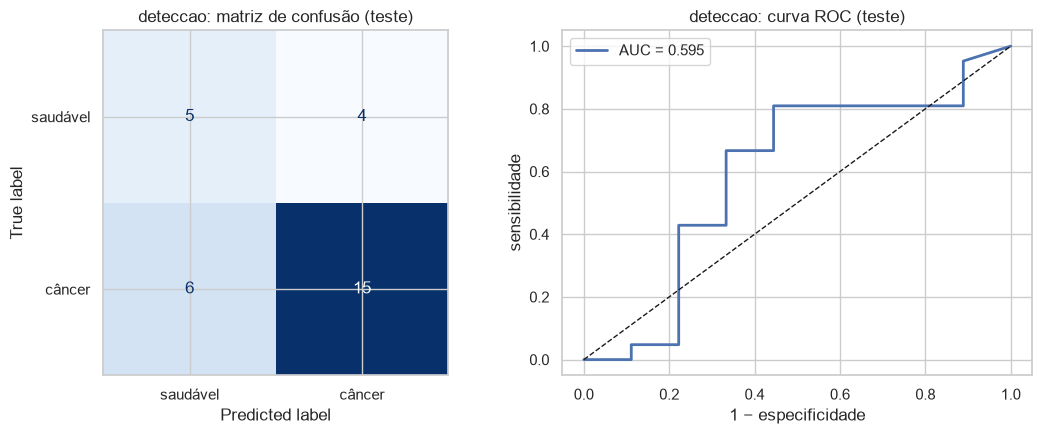

In [6]:
modelo_det, Xd_tr, Xd_te, yd_tr, yd_te = holdout(X, y_det, ["saudável", "câncer"], "deteccao")

## 5. Tarefa 2 — Tecido de origem: CRC vs STAD (só amostras com câncer)

In [7]:
cancer = meta.index[meta["grupo"] != "NC"]
X_too = X.loc[cancer]
y_too = (meta.loc[cancer, "grupo"] == "STAD").astype(int)   # 1 = STAD (estômago), 0 = CRC (colorretal)
print(y_too.value_counts().rename({1: "STAD", 0: "CRC"}))
res_too = nested_cv(X_too, y_too)

grupo
STAD    35
CRC     32
Name: count, dtype: int64


Nested CV (média ± desvio):


,mean,std
acuracia,0.711,0.119
precisao,0.729,0.143
sensibilidade,0.752,0.183
especificidade,0.663,0.191
f1,0.726,0.122
roc_auc,0.789,0.136


Hiperparâmetros escolhidos nos folds:


rf__max_features  selecao__k
sqrt              100           9
                  500           3
0.1               2000          2
sqrt              2000          1
Name: vezes, dtype: int64

melhores hiperparâmetros: {'rf__max_features': 0.1, 'selecao__k': 500}


,teste (21 amostras)
acuracia,0.810
precisao,0.889
sensibilidade,0.727
especificidade,0.900
f1,0.800
roc_auc,0.873


              precision    recall  f1-score   support

         CRC       0.75      0.90      0.82        10
        STAD       0.89      0.73      0.80        11

    accuracy                           0.81        21
   macro avg       0.82      0.81      0.81        21
weighted avg       0.82      0.81      0.81        21



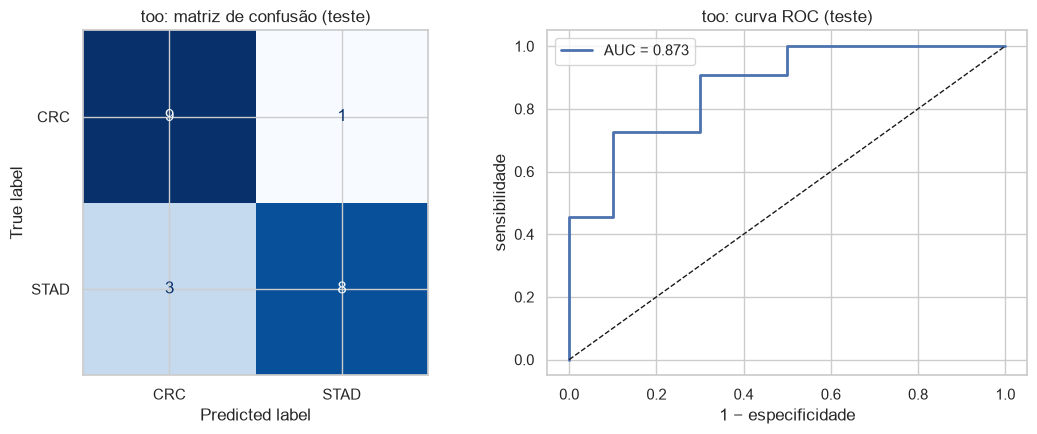

In [8]:
modelo_too, Xt_tr, Xt_te, yt_tr, yt_te = holdout(X_too, y_too, ["CRC", "STAD"], "too")

## 6. Fluxo hierárquico (detecção → TOO), como no artigo

Usa as predições **fora da amostra** (*out-of-fold*, via `cross_val_predict`) para todas as 98 amostras:
- etapa 1 decide câncer vs saudável;
- etapa 2 (treinada só com câncer) atribui CRC/STAD a quem foi positivo.

Hiperparâmetros fixados nos valores mais escolhidos na nested CV para manter o custo baixo.

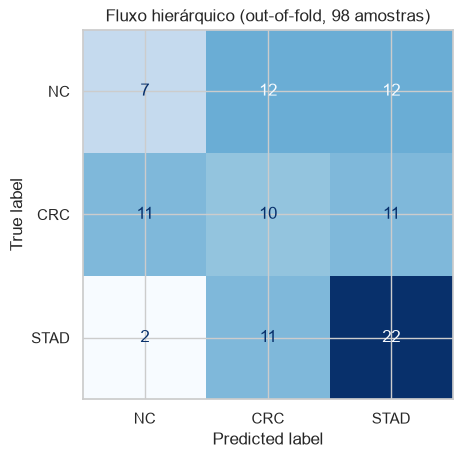

              precision    recall  f1-score   support

          NC       0.35      0.23      0.27        31
         CRC       0.30      0.31      0.31        32
        STAD       0.49      0.63      0.55        35

    accuracy                           0.40        98
   macro avg       0.38      0.39      0.38        98
weighted avg       0.38      0.40      0.38        98



In [9]:
def pipe_fixo(res_search_params):
    p = make_pipeline(); p.set_params(**res_search_params); return p

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
p_det = pipe_fixo({"selecao__k": 500, "rf__max_features": "sqrt"})
p_too = pipe_fixo({"selecao__k": 500, "rf__max_features": "sqrt"})

oof_det = pd.Series(cross_val_predict(p_det, X, y_det, cv=cv5, method="predict_proba")[:, 1], index=X.index)
oof_too = pd.Series(cross_val_predict(p_too, X_too, y_too, cv=cv5, method="predict_proba")[:, 1], index=X_too.index)

# Para saudáveis classificados como câncer, a etapa 2 precisa de um modelo treinado em todos os cânceres
p_too_full = pipe_fixo({"selecao__k": 500, "rf__max_features": "sqrt"}).fit(X_too, y_too)
final = pd.Series("NC", index=X.index)
pos = oof_det.index[oof_det >= .5]
for s in pos:
    p = oof_too[s] if s in oof_too.index else p_too_full.predict_proba(X.loc[[s]])[0, 1]
    final[s] = "STAD" if p >= .5 else "CRC"

ordem = ["NC", "CRC", "STAD"]
cm = confusion_matrix(meta["grupo"], final, labels=ordem)
ConfusionMatrixDisplay(cm, display_labels=ordem).plot(cmap="Blues", colorbar=False)
plt.title("Fluxo hierárquico (out-of-fold, 98 amostras)"); plt.savefig(FIG / "hierarquico_cm.png", dpi=150, bbox_inches="tight"); plt.show()
print(classification_report(meta["grupo"], final, labels=ordem, zero_division=0))

## 7. Confundidores: lote `mix` e idade

**7a. Amostras que cruzam o lote.** Se o modelo de detecção aprendeu "lote mix ⇒ saudável", ele deve errar justamente:
- nos **6 saudáveis não-mix** (chamando-os de câncer), e
- nos **2 CRC mix** (chamando-os de saudáveis).

In [10]:
tab = meta[["grupo", "lote_mix", "age"]].copy()
tab["prob_cancer"] = oof_det.round(3)
tab["pred"] = np.where(oof_det >= .5, "câncer", "saudável")
tab["acertou"] = (oof_det >= .5).astype(int) == y_det
display(tab.groupby(["grupo", "lote_mix"]).agg(n=("acertou", "size"), taxa_acerto=("acertou", "mean"),
                                               prob_cancer_media=("prob_cancer", "mean")).round(3))
display(tab[(tab.grupo == "NC") & ~tab.lote_mix | (tab.grupo == "CRC") & tab.lote_mix])

n  taxa_acerto  prob_cancer_media
grupo lote_mix                                    
CRC   False     30        0.633              0.552
      True       2        1.000              0.613
NC    False      6        0.000              0.571
      True      25        0.280              0.594
STAD  False     35        0.943              0.634

,grupo,lote_mix,age,prob_cancer,pred,acertou
title,,,,,,
CRC-PKU-mix0-me,CRC,True,83,0.646,câncer,True
CRC-PKU-mix1-me,CRC,True,70,0.580,câncer,True
NC-PKU-10-me,NC,False,82,0.514,câncer,False
NC-PKU-11-me,NC,False,28,0.622,câncer,False
NC-PKU-12-me,NC,False,37,0.602,câncer,False
NC-PKU-13-me,NC,False,54,0.546,câncer,False
NC-PKU-14-me,NC,False,61,0.598,câncer,False
NC-PKU-9-me,NC,False,39,0.546,câncer,False


**7b. A idade sozinha prevê câncer?** Um RF usando **só a idade** serve de linha de base: se ele já fosse muito bom, parte do desempenho do modelo de metilação poderia vir da idade.

In [11]:
rf_idade = RandomForestClassifier(n_estimators=500, min_samples_leaf=5, class_weight="balanced", random_state=RANDOM_STATE)
prob_idade = cross_val_predict(rf_idade, meta[["age"]], y_det, cv=cv5, method="predict_proba")[:, 1]
print(f"AUC só com idade: {roc_auc_score(y_det, prob_idade):.3f}")
print(f"AUC metilação (out-of-fold): {roc_auc_score(y_det, oof_det):.3f}")

AUC só com idade: 0.703
AUC metilação (out-of-fold): 0.526


## 8. Quais promotores mais contribuem?

*Permutation importance* no conjunto de **teste** do hold-out: embaralha uma feature por vez e mede quanto o AUC cai. É mais confiável que a importância por impureza (que favorece features com muitos valores distintos).

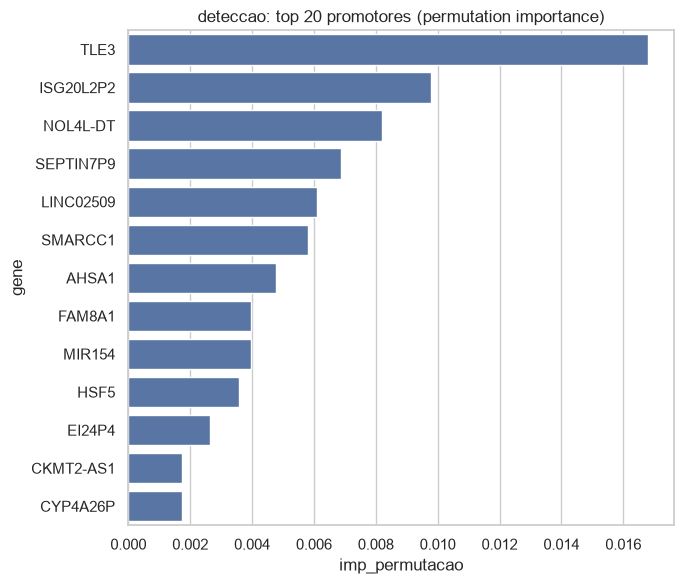

,promotor,imp_permutacao,imp_impureza,gene_id,gene,chrom
27,promoter_ENSG00000140332.15|2501,0.016799,0.031256,ENSG00000140332,TLE3,15
48,promoter_ENSG00000224579.1|2501,0.010450,0.020703,ENSG00000224579,NaN,19
19,promoter_ENSG00000255710.2|2501,0.009788,0.015370,ENSG00000255710,ISG20L2P2,11
55,promoter_ENSG00000204393.7|2501,0.008201,0.015174,ENSG00000204393,NOL4L-DT,20
17,promoter_ENSG00000270117.1|2501,0.007143,0.014256,ENSG00000270117,NaN,11
95,promoter_ENSG00000253942.1|2501,0.007011,0.007846,ENSG00000253942,NaN,8
14,promoter_ENSG00000120555.13|2501,0.006878,0.022196,ENSG00000120555,SEPTIN7P9,10
69,promoter_ENSG00000250263.1|2501,0.006085,0.005807,ENSG00000250263,LINC02509,4
65,promoter_ENSG00000173473.10|2501,0.005820,0.003965,ENSG00000173473,SMARCC1,3
24,promoter_ENSG00000100591.7|2501,0.004762,0.007328,ENSG00000100591,AHSA1,14


In [12]:
def importancias(modelo, X_te, y_te, cols, tag, top=20):
    nomes = feature_names(modelo, cols)
    Xs = modelo[:-1].transform(X_te)                       # aplica filtro + seleção
    pi = permutation_importance(modelo.named_steps["rf"], Xs, y_te, scoring="roc_auc",
                                n_repeats=20, random_state=RANDOM_STATE, n_jobs=-1)
    imp = (pd.DataFrame({"promotor": nomes, "imp_permutacao": pi.importances_mean,
                         "imp_impureza": modelo.named_steps["rf"].feature_importances_})
             .join(feat, on="promotor").sort_values("imp_permutacao", ascending=False))
    imp.to_csv(TAB / f"importancias_{tag}.csv", index=False)
    t = imp.head(top)
    plt.figure(figsize=(7, 6)); sns.barplot(data=t, y="gene", x="imp_permutacao", color="C0")
    plt.title(f"{tag}: top {top} promotores (permutation importance)"); plt.tight_layout()
    plt.savefig(FIG / f"importancias_{tag}.png", dpi=150); plt.show()
    return imp

imp_det = importancias(modelo_det, Xd_te, yd_te, X.columns, "deteccao")
imp_det.head(15)

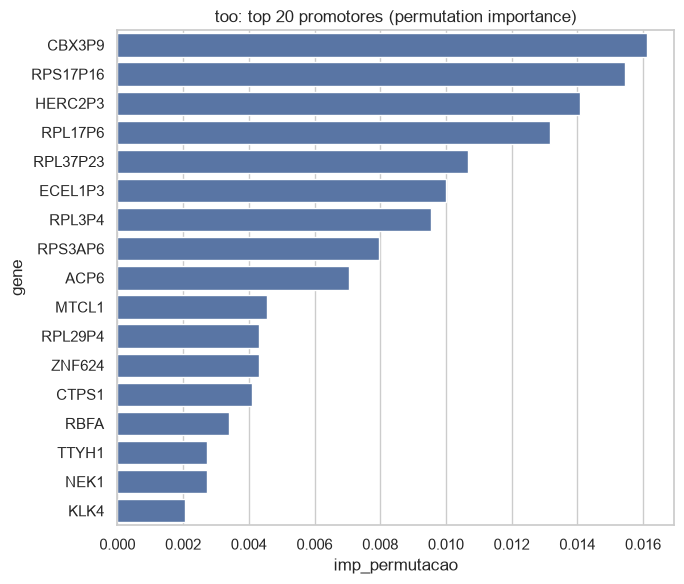

,promotor,imp_permutacao,imp_impureza,gene_id,gene,chrom
151,promoter_ENSG00000260784.1|2501,0.018864,0.022414,ENSG00000260784,NaN,15
417,promoter_ENSG00000217241.1|2501,0.016136,0.009588,ENSG00000217241,CBX3P9,6
330,promoter_ENSG00000232346.1|2501,0.015455,0.007386,ENSG00000232346,RPS17P16,22
146,promoter_ENSG00000180229.12|2501,0.014091,0.035821,ENSG00000180229,HERC2P3,15
21,promoter_ENSG00000226084.5|2501,0.013182,0.014600,ENSG00000226084,RPL17P6,1
260,promoter_ENSG00000243680.1|2501,0.010682,0.006363,ENSG00000243680,RPL37P23,19
301,promoter_ENSG00000230122.1|2501,0.010000,0.012060,ENSG00000230122,ECEL1P3,2
138,promoter_ENSG00000232573.1|2501,0.009545,0.003967,ENSG00000232573,RPL3P4,14
159,promoter_ENSG00000234797.5|2501,0.007955,0.012722,ENSG00000234797,RPS3AP6,15
28,promoter_ENSG00000162836.11|2501,0.007045,0.008021,ENSG00000162836,ACP6,1


In [13]:
imp_too = importancias(modelo_too, Xt_te, yt_te, X_too.columns, "too")
imp_too.head(15)

## 9. Demonstração de vazamento (para o relatório)

Mesmo modelo, mas com a seleção de features feita **no dataset inteiro antes** da validação cruzada (errado) vs **dentro** de cada fold (certo).
Para deixar o efeito evidente, usamos **rótulos embaralhados** (aleatórios): não existe sinal real, então o AUC honesto deveria ficar perto de 0,5.

In [14]:
rng = np.random.default_rng(RANDOM_STATE)
y_rand = pd.Series(rng.permutation(y_det.values), index=y_det.index)

# ERRADO: seleciona os 500 promotores mais associados ao rótulo usando TODAS as amostras
sel = SelectKBest(f_classif, k=500).fit(X, y_rand)
rf = RandomForestClassifier(n_estimators=500, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1)
prob_errado = cross_val_predict(rf, X.loc[:, sel.get_support()], y_rand, cv=cv5, method="predict_proba")[:, 1]

# CERTO: seleção dentro do pipeline
prob_certo = cross_val_predict(pipe_fixo({"selecao__k": 500, "rf__max_features": "sqrt"}),
                               X, y_rand, cv=cv5, method="predict_proba")[:, 1]
print(f"Rótulos aleatórios — AUC com vazamento: {roc_auc_score(y_rand, prob_errado):.3f}")
print(f"Rótulos aleatórios — AUC sem vazamento: {roc_auc_score(y_rand, prob_certo):.3f}")

Rótulos aleatórios — AUC com vazamento: 0.838
Rótulos aleatórios — AUC sem vazamento: 0.265


In [15]:
# salva um resumo das métricas
resumo = pd.concat({"deteccao": res_det.agg(["mean", "std"]).T, "too": res_too.agg(["mean", "std"]).T}, axis=0).round(3)
resumo.to_csv(TAB / "metricas_nested_cv.csv"); resumo

mean    std
deteccao acuracia        0.623  0.067
         precisao        0.711  0.034
         sensibilidade   0.763  0.145
         especificidade  0.324  0.165
         f1              0.728  0.074
         roc_auc         0.553  0.182
too      acuracia        0.711  0.119
         precisao        0.729  0.143
         sensibilidade   0.752  0.183
         especificidade  0.663  0.191
         f1              0.726  0.122
         roc_auc         0.789  0.136